In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

## Q1

In [2]:
def get_neighbors(i, j, rows, cols, con):
    if con == 4:
        directions = [(0, 1), (1, 0), (0, -1), (-1, 0)]
    elif con == 8:
        directions = [
            (0, 1),
            (1, 0),
            (0, -1),
            (-1, 0),
            (1, 1),
            (1, -1),
            (-1, 1),
            (-1, -1),
        ]

    neighbors = []

    for di, dj in directions:
        ni = i + di
        nj = j + dj

        if 0 <= ni < rows and 0 <= nj < cols:
            neighbors.append((ni, nj))

    return neighbors

In [3]:
def connected_components(Im_binary, con):
    rows, cols = Im_binary.shape
    visited = np.zeros((rows, cols), dtype=bool)
    regions = []

    for i in range(rows):
        for j in range(cols):
            if Im_binary[i, j] == 1 and not visited[i, j]:
                queue = [(i, j)]
                visited[i, j] = True
                region = []
                head = 0

                while head < len(queue):
                    x, y = queue[head]
                    head += 1
                    region.append((x, y))

                    for nx, ny in get_neighbors(x, y, rows, cols, con):
                        if Im_binary[nx, ny] == 1 and not visited[nx, ny]:
                            visited[nx, ny] = True
                            queue.append((nx, ny))

                regions.append(region)

    return regions

In [4]:
def Region_adjacency(Im_binary, Ri, Rj, con):
    rows, cols = Im_binary.shape
    region_j = set(Rj)

    for x, y in Ri:
        for nx, ny in get_neighbors(x, y, rows, cols, con):
            if (nx, ny) in region_j:
                return 1

    return 0

In [5]:
def Boundary_extract(Im_binary, con):
    rows, cols = Im_binary.shape
    regions = connected_components(Im_binary, con)
    Im_boundary = np.zeros((rows, cols), dtype=np.uint8)
    boundary_counts = []

    for region in regions:
        region_set = set(region)
        count = 0

        for x, y in region:
            boundary = False

            if x == 0 or x == rows - 1 or y == 0 or y == cols - 1:
                boundary = True

            for nx, ny in get_neighbors(x, y, rows, cols, con):
                if (nx, ny) not in region_set:
                    boundary = True
                    break

            if boundary:
                Im_boundary[x, y] = 1
                count += 1

        boundary_counts.append(count)

    return Im_boundary, boundary_counts

In [6]:
def Foreground_background(Im_binary):
    rows, cols = Im_binary.shape
    Im_fg = np.zeros((rows, cols), dtype=np.uint8)
    Im_bg = np.zeros((rows, cols), dtype=np.uint8)

    foreground_count = 0
    background_count = 0

    for i in range(rows):
        for j in range(cols):
            if Im_binary[i, j] == 1:
                Im_fg[i, j] = 1
                foreground_count += 1
            else:
                Im_bg[i, j] = 1
                background_count += 1

    return Im_fg, Im_bg, foreground_count, background_count

In [7]:
Im_binary = np.array(
    [
        [0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 1, 0, 0, 0, 0, 0],
        [0, 1, 1, 0, 0, 1, 1, 0],
        [0, 0, 0, 0, 1, 1, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 1, 1, 0, 0, 0, 0],
        [0, 0, 1, 1, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0],
    ],
    dtype=np.uint8,
)

regions = connected_components(Im_binary, 4)
Im_boundary, boundary_counts = Boundary_extract(Im_binary, 4)
Im_fg, Im_bg, foreground_count, background_count = Foreground_background(Im_binary)

print("Number of connected regions =", len(regions))

for i in range(len(regions)):
    print("Region", i + 1, "=", len(regions[i]), "pixels")

print(
    "Region_adjacency(R1, R2) =", Region_adjacency(Im_binary, regions[0], regions[1], 4)
)

for i in range(len(boundary_counts)):
    print("Boundary pixel count: Region", i + 1, "=", boundary_counts[i])

print("Foreground pixel count =", foreground_count)
print("Background pixel count =", background_count)

Number of connected regions = 3
Region 1 = 4 pixels
Region 2 = 4 pixels
Region 3 = 4 pixels
Region_adjacency(R1, R2) = 0
Boundary pixel count: Region 1 = 4
Boundary pixel count: Region 2 = 4
Boundary pixel count: Region 3 = 4
Foreground pixel count = 12
Background pixel count = 52


## Q2

In [8]:
def histogram(Im):
    rows, cols = Im.shape
    hist = np.zeros(256, dtype=np.int64)

    for i in range(rows):
        for j in range(cols):
            hist[int(Im[i, j])] += 1

    return hist

In [9]:
def hist_eq(Im):
    hist = [0] * 256

    for pixel in Im.ravel():
        hist[int(pixel)] += 1
    cdf = [0] * 256
    cdf[0] = hist[0]

    for i in range(1, 256):
        cdf[i] = cdf[i - 1] + hist[i]

    lut = [0] * 256
    denominator = Im.size

    for i in range(256):
        if denominator == 0:
            lut[i] = 0
        else:
            value = round((cdf[i]) * 255 / denominator)

            if value < 0:
                value = 0
            elif value > 255:
                value = 255

            lut[i] = value
    result = np.empty_like(Im)

    for i in range(Im.shape[0]):
        for j in range(Im.shape[1]):
            result[i, j] = lut[int(Im[i, j])]

    return result

In [10]:
def plot_histogram(Im, title):
    hist = histogram(Im)
    x = []
    y = []

    for i in range(256):
        x.append(i)
        y.append(hist[i])

    plt.plot(x, y)
    plt.title(title)
    plt.xlim(0, 255)

In [11]:
def gamma_correction(Im, gamma):
    rows, cols = Im.shape
    result = np.zeros((rows, cols), dtype=np.uint8)

    for i in range(rows):
        for j in range(cols):
            r = int(Im[i, j]) / 255.0
            value = 255.0 * math.pow(r, gamma)

            if value < 0:
                value = 0
            elif value > 255:
                value = 255

            result[i, j] = int(value + 0.5)

    return result

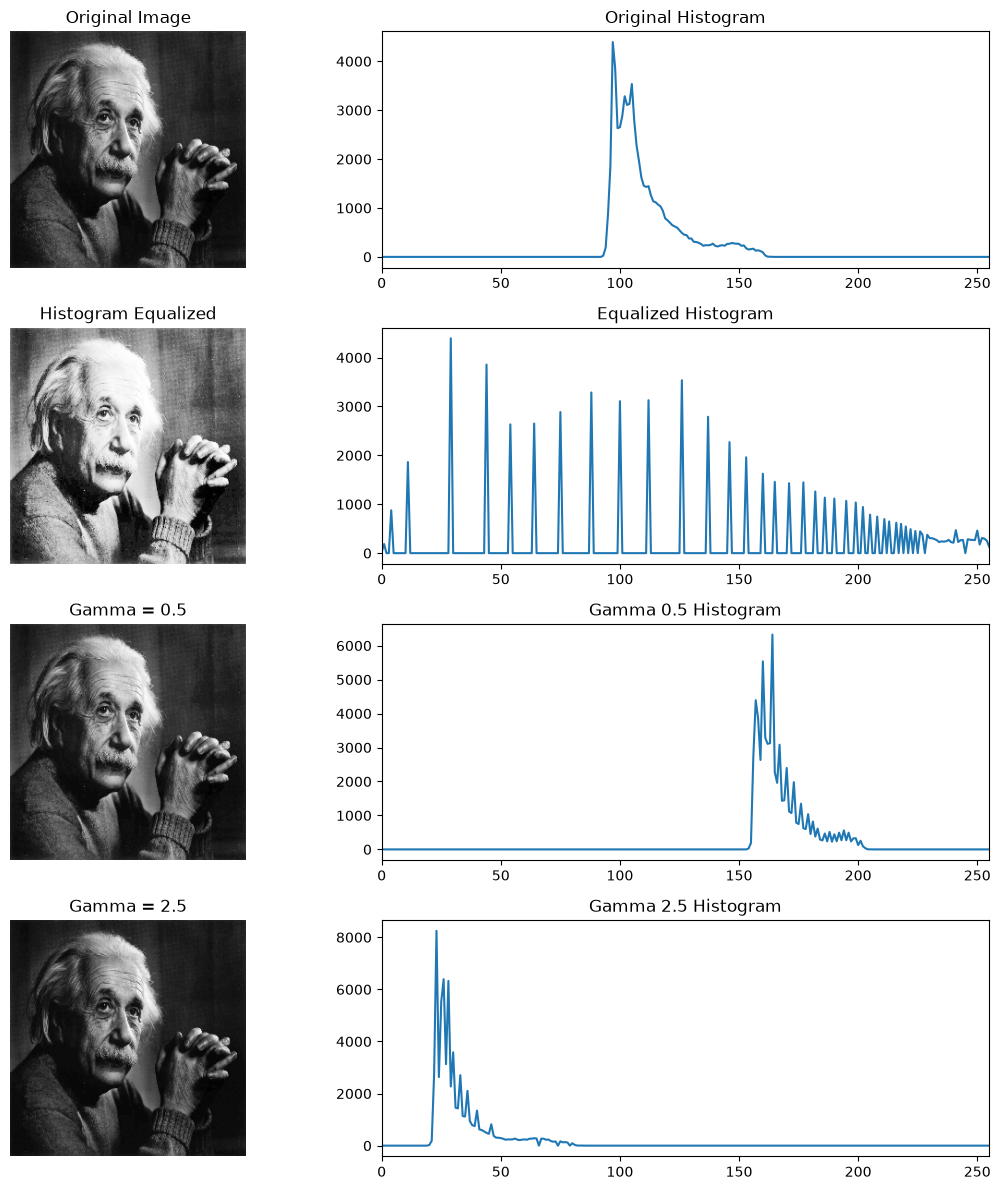

In [12]:
img = cv2.imread("input.png", cv2.IMREAD_GRAYSCALE)

equalized = hist_eq(img)
gamma_05 = gamma_correction(img, 0.5)
gamma_25 = gamma_correction(img, 2.5)

plt.figure(figsize=(12, 12))

plt.subplot(4, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(4, 2, 2)
plot_histogram(img, "Original Histogram")

plt.subplot(4, 2, 3)
plt.imshow(equalized, cmap="gray")
plt.title("Histogram Equalized")
plt.axis("off")

plt.subplot(4, 2, 4)
plot_histogram(equalized, "Equalized Histogram")

plt.subplot(4, 2, 5)
plt.imshow(gamma_05, cmap="gray")
plt.title("Gamma = 0.5")
plt.axis("off")

plt.subplot(4, 2, 6)
plot_histogram(gamma_05, "Gamma 0.5 Histogram")

plt.subplot(4, 2, 7)
plt.imshow(gamma_25, cmap="gray")
plt.title("Gamma = 2.5")
plt.axis("off")

plt.subplot(4, 2, 8)
plot_histogram(gamma_25, "Gamma 2.5 Histogram")

plt.tight_layout()
plt.show()

## Q3

In [13]:
def global_threshold(Im):
    rows, cols = Im.shape
    threshold = (np.max(Im) - np.min(Im)) / 3.0
    result = np.zeros((rows, cols), dtype=np.uint8)

    for i in range(rows):
        for j in range(cols):
            if int(Im[i, j]) >= threshold:
                result[i, j] = 1

    return result, threshold

In [14]:
def local_threshold(Im, block_size=32):
    rows, cols = Im.shape
    result = np.zeros((rows, cols), dtype=np.uint8)
    thresholds = []
    block_number = 1

    for r in range(0, rows, block_size):
        for c in range(0, cols, block_size):
            block = Im[r : r + block_size, c : c + block_size]
            threshold = (np.max(block) - np.min(block)) / 3.0
            thresholds.append(threshold)

            for i in range(r, r + block_size):
                for j in range(c, c + block_size):
                    if int(Im[i, j]) >= threshold:
                        result[i, j] = 1

            block_number += 1

    return result, thresholds

In [15]:
def difference_image(global_binary, local_binary):
    rows, cols = global_binary.shape
    result = np.zeros((rows, cols), dtype=np.int16)

    for i in range(rows):
        for j in range(cols):
            result[i, j] = int(local_binary[i, j]) - int(global_binary[i, j])

    return result

Global threshold = 74.66666666666667
Local Thresholds:
Block 1 = 47.333333333333336
Block 2 = 60.333333333333336
Block 3 = 61.666666666666664
Block 4 = 4.0
Block 5 = 3.3333333333333335
Block 6 = 46.333333333333336
Block 7 = 51.333333333333336
Block 8 = 55.0
Block 9 = 49.333333333333336
Block 10 = 62.0
Block 11 = 70.66666666666667
Block 12 = 16.333333333333332
Block 13 = 15.333333333333334
Block 14 = 62.666666666666664
Block 15 = 63.333333333333336
Block 16 = 55.333333333333336
Block 17 = 61.666666666666664
Block 18 = 68.66666666666667
Block 19 = 74.66666666666667
Block 20 = 10.0
Block 21 = 12.0
Block 22 = 67.0
Block 23 = 65.66666666666667
Block 24 = 58.666666666666664
Block 25 = 49.333333333333336
Block 26 = 67.66666666666667
Block 27 = 70.66666666666667
Block 28 = 65.66666666666667
Block 29 = 58.666666666666664
Block 30 = 69.0
Block 31 = 69.66666666666667
Block 32 = 64.33333333333333
Block 33 = 48.666666666666664
Block 34 = 46.333333333333336
Block 35 = 51.333333333333336
Block 36 = 5

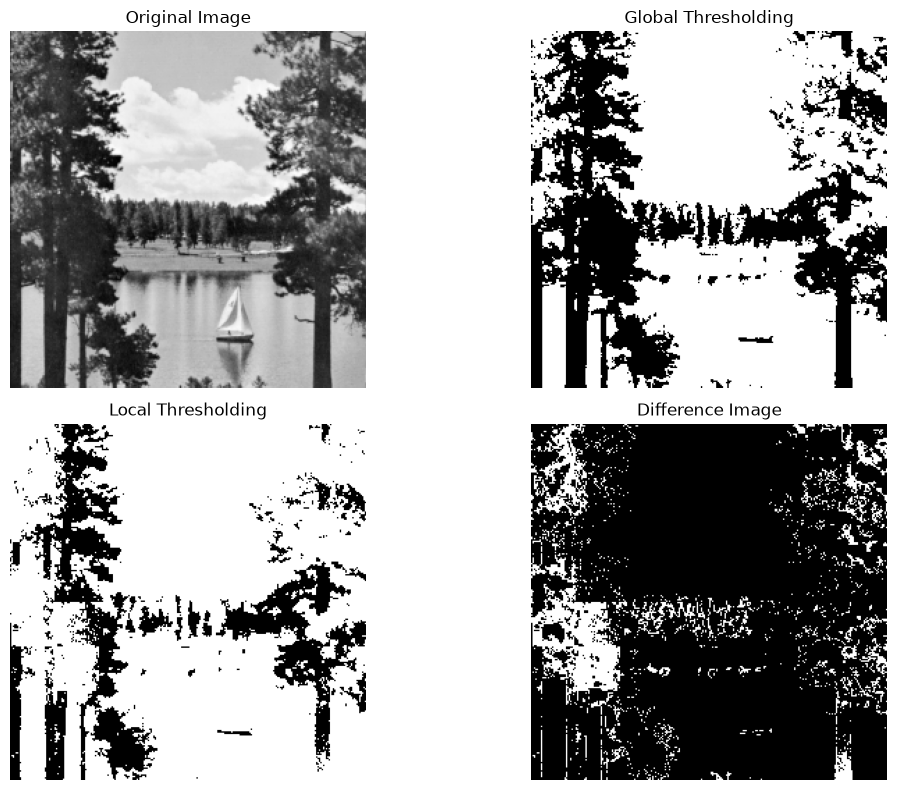

In [16]:
lake = cv2.imread("lake.png", cv2.IMREAD_GRAYSCALE)

global_binary, global_T = global_threshold(lake)
local_binary, local_thresholds = local_threshold(lake, 32)
difference = difference_image(global_binary, local_binary)

print("Global threshold =", global_T)
print("Local Thresholds:")

for i in range(len(local_thresholds)):
    print("Block", i + 1, "=", local_thresholds[i])

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(lake, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(global_binary, cmap="gray")
plt.title("Global Thresholding")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(local_binary, cmap="gray")
plt.title("Local Thresholding")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(difference, cmap="gray")
plt.title("Difference Image")
plt.axis("off")

plt.tight_layout()
plt.show()

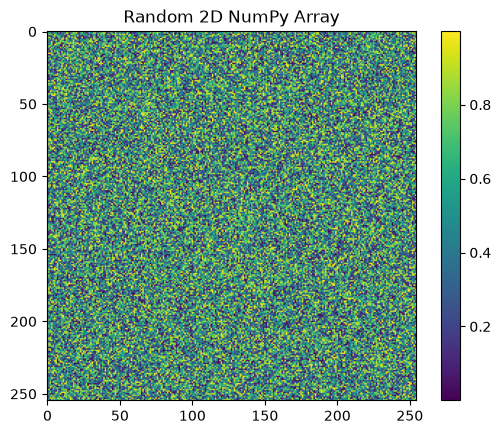

In [17]:
arr = np.random.rand(255,255)

plt.imshow(arr, cmap="viridis")
plt.colorbar()
plt.title("Random 2D NumPy Array")
plt.show()